# Manufacturing defect detection: frozen versus adapted Vision Transformer
**Post-EDA notebook · MVTec AD (bottle and cable categories)**

**Research question:** Does partially adapting a pretrained ViT with *synthetic* defects improve detection of *real* manufacturing defects, compared with the same ViT left frozen, when both use an identical patch nearest-neighbour detector?

**Approach in one paragraph.** A pretrained ViT-S/16 (ImageNet-21k → ImageNet-1k) turns each 224×224 image into a 14×14 grid of patch embeddings. A memory bank of patch embeddings from *normal* training images is stored per category, and a test image is scored by how far its most unusual patch is from anything in that bank (cosine distance, max over patches). The **frozen** condition uses the pretrained weights directly (embedding extraction). The **adapted** condition first fine-tunes the last two transformer blocks on CutPaste-style synthetic defects created from normal images only, then discards the auxiliary head and uses the same detector. A zero-shot **CLIP** model (Section 8) is included as a multimodal reference that uses no product-specific training images at all.

This is an educational implementation inspired by CutPaste (Li et al., 2021) and patch-memory detectors such as PatchCore (Roth et al., 2022); it is not a reproduction of either.

**How to run:** Runtime → Change runtime type → GPU (a T4 is enough), then run all cells in order. Completed fine-tuning trials and memory banks are reused from Google Drive, so a re-run after the first full run takes only a few minutes. The notebook restores data from the EDA manifests in `Manufacturing_Defects/outputs` and does not need the EDA notebook's Python variables.

## Notebook map
| Section | Content |
|---|---|
| 1 | Restore data and the exact EDA partitions; leakage audit |
| 2 | Model, preprocessing and synthetic-defect generation |
| 3 | Fine-tuning with validation-based checkpoint selection |
| 4 | Nearest-neighbour detector and normal-only threshold calibration |
| 5 | Final test evaluation (first use of real test labels) |
| 6 | ROC/PR curves, confusion matrices, per-defect recall, paired comparison |
| 6b | Deeper analysis: score distributions, per-defect AUROC, defect size, realistic prevalence |
| 7 | Failure cases and anomaly heatmaps |
| 8 | Multimodal reference: zero-shot CLIP |
| 9 | Predict your own image |
| 10 | Findings, limitations and ethical considerations |

## Evaluation protocol (fixed before looking at test results)
1. Keep the EDA reference/validation/test partitions. Split the normal validation set equally into **selection** and **calibration** subsets.
2. Only normal reference images are used to create synthetic cut-and-paste training examples. Their masks are generated automatically; real defect masks are never training targets.
3. Fine-tune the final two transformer blocks, the final norm and an auxiliary patch head. Compare two predeclared learning rates and select the epoch/configuration on **fixed synthetic selection examples**.
4. Discard the auxiliary head. Both ViT methods use L2-normalised patch tokens, the same reference-bank patch indices, cosine nearest-neighbour distance and the maximum patch distance as the image score.
5. For each method and category, set the threshold using only normal calibration scores (empirical 95th percentile). This targets a ~5% false-alarm rate on calibration data; it is not a guaranteed future rate.
6. Evaluate all fixed methods once on the original test images. Real test labels and masks are used only for evaluation and illustrations.

The selection objective (synthetic patch BCE) is a proxy, not real-defect recall; that mismatch is a stated limitation. Small calibration sets make thresholds uncertain.

In [1]:
%pip -q install "timm>=1.0.15,<1.1" scikit-learn pandas matplotlib pillow tqdm


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, math, random, time, hashlib, tarfile, shutil, gc, platform
from pathlib import Path
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance
from tqdm.auto import tqdm
from IPython.display import display
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, balanced_accuracy_score,
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve)

PROJECT = Path('/content/drive/MyDrive/Manufacturing_Defects')
EDA_DIR = PROJECT / 'outputs'
DATA_DIR = Path('/content/mvtec_ad')
# Change RUN_NAME for a genuinely new predeclared experiment, not to hide failed runs.
RUN_NAME = 'vit_synthetic_adaptation_v1'
RUN_DIR = PROJECT / 'experiments' / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
CATEGORIES = ['bottle', 'cable']
MODEL_NAME = 'vit_small_patch16_224.augreg_in21k_ft_in1k'
SEED = 42
IMAGE_SIZE = 224
PATCH_SIZE = 16
BATCH_SIZE = 8
MAX_EPOCHS = 12
PATIENCE = 3
LEARNING_RATES = [1e-5, 3e-5]
MAX_BANK_PATCHES = 10000
TARGET_FPR = 0.05
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
print('Device:', DEVICE)
if AMP:
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('Switch to a GPU runtime before running the training cells; CPU will be slow.')

config = dict(model=MODEL_NAME, seed=SEED, categories=CATEGORIES,
    image_size=IMAGE_SIZE, patch_size=PATCH_SIZE, batch_size=BATCH_SIZE,
    max_epochs=MAX_EPOCHS, patience=PATIENCE, learning_rates=LEARNING_RATES,
    max_bank_patches=MAX_BANK_PATCHES, target_fpr=TARGET_FPR,
    trainable_blocks=2, weight_decay=0.01, synthetic_positive_weight=5.0,
    distance='cosine', image_aggregation='max', calibration_quantile_method='higher')
config_path = RUN_DIR / 'config.json'
if config_path.exists():
    assert json.loads(config_path.read_text()) == config, (
        'Settings changed: use a new RUN_NAME to avoid mixing incompatible results.')
else:
    config_path.write_text(json.dumps(config, indent=2))
versions = {p: metadata.version(p) for p in
            ['torch','torchvision','timm','numpy','pandas','scikit-learn','Pillow']}
versions['python'] = platform.python_version()
(RUN_DIR / 'environment.json').write_text(json.dumps(versions, indent=2))
print('Outputs:', RUN_DIR)


Mounted at /content/drive
Device: cuda
GPU: Tesla T4
Outputs: /content/drive/MyDrive/Manufacturing_Defects/experiments/vit_synthetic_adaptation_v1


## 1. Restore data and the exact EDA partitions
Keep the original archive in `Manufacturing_Defects/archives`. This recovery cell extracts selected image files only when the local category folders are missing. It never deletes your Drive archive. A partial extraction is caught by the manifest file checks below.


In [3]:
DATA_DIR.mkdir(parents=True, exist_ok=True)
need_extraction = any(not (DATA_DIR / c / 'train' / 'good').is_dir()
                      for c in CATEGORIES)
if need_extraction:
    archives = sorted((PROJECT / 'archives').glob('*.tar.xz'))
    assert archives, 'No .tar.xz archive found in the Drive archives folder.'
    for archive_path in archives:
        local = Path('/content') / ('restore_' + archive_path.name)
        shutil.copy2(archive_path, local)
        with tarfile.open(local, 'r:xz') as archive:
            for member in tqdm(archive, desc=archive_path.name):
                if not member.isfile() or not member.name.lower().endswith('.png'):
                    continue
                parts = Path(member.name).parts
                start = next((i for i,p in enumerate(parts) if p in CATEGORIES), None)
                if start is None:
                    continue
                target = DATA_DIR / Path(*parts[start:])
                if not target.resolve().is_relative_to(DATA_DIR.resolve()):
                    raise ValueError('Unsafe archive path')
                target.parent.mkdir(parents=True, exist_ok=True)
                with archive.extractfile(member) as src, target.open('wb') as dst:
                    shutil.copyfileobj(src, dst)
        local.unlink()

def read_manifest(name):
    path = EDA_DIR / f'{name}_manifest.csv'
    assert path.is_file(), f'Missing {path}. Run the previous EDA partition cell first.'
    frame = pd.read_csv(path)
    frame = frame[frame.category.isin(CATEGORIES)].copy()
    frame['relative_path'] = frame.relative_path.str.replace('\\', '/', regex=False)
    frame['image_path'] = frame.relative_path.map(lambda p: str(DATA_DIR / p))
    assert not frame.relative_path.duplicated().any(), 'Duplicate paths within manifest.'
    missing = [p for p in frame.image_path if not Path(p).is_file()]
    assert not missing, f'Missing {len(missing)} files; first: {missing[:2]}'
    return frame.sort_values('relative_path').reset_index(drop=True)

reference_df = read_manifest('reference')
old_val_df = read_manifest('validation')
test_df = read_manifest('test')
assert reference_df.is_anomaly.eq(0).all() and old_val_df.is_anomaly.eq(0).all()
for frame in [reference_df, old_val_df]:
    assert frame.relative_path.map(lambda p: Path(p).parts[1] == 'train').all()
assert test_df.relative_path.map(lambda p: Path(p).parts[1] == 'test').all()

selection_parts, calibration_parts = [], []
for category in CATEGORIES:
    subset = old_val_df[old_val_df.category == category]
    assert len(subset) >= 4, f'Too few validation images for {category}'
    selection, calibration = train_test_split(subset, test_size=0.5, random_state=SEED)
    selection_parts.append(selection)
    calibration_parts.append(calibration)
selection_df = pd.concat(selection_parts).sort_values('relative_path').reset_index(drop=True)
calibration_df = pd.concat(calibration_parts).sort_values('relative_path').reset_index(drop=True)
partitions = {'reference': reference_df, 'selection': selection_df,
              'calibration': calibration_df, 'test': test_df}

# Verify paths and decoded image content do not cross partitions.
seen_paths, seen_hashes, audit_rows = {}, {}, []
for name, frame in partitions.items():
    for row in tqdm(frame.itertuples(), total=len(frame), desc=f'Audit {name}'):
        assert row.relative_path not in seen_paths, f'Path leakage: {row.relative_path}'
        seen_paths[row.relative_path] = name
        with Image.open(row.image_path) as image:
            arr = np.array(image.convert('RGB'))
        digest = hashlib.sha256(str(arr.shape).encode() + arr.tobytes()).hexdigest()
        if digest in seen_hashes and seen_hashes[digest] != name:
            raise ValueError('Exact duplicate image crosses partitions. Resolve before training.')
        seen_hashes[digest] = name
        audit_rows.append(dict(partition=name, relative_path=row.relative_path, sha256=digest))
    frame.drop(columns='image_path').to_csv(RUN_DIR / f'{name}_manifest.csv', index=False)
audit = pd.DataFrame(audit_rows)
audit_path = RUN_DIR / 'content_audit.csv'
if audit_path.exists():
    assert pd.read_csv(audit_path).equals(audit), 'Data/partitions changed. Use a new RUN_NAME.'
audit.to_csv(audit_path, index=False)
display(pd.DataFrame({n: f.groupby('category').size() for n,f in partitions.items()}))
print('Exact duplicate audit passed. Near-duplicate images are not ruled out by this check.')


mvtec_anomaly_detection.tar.xz: 0it [00:00, ?it/s]

Audit reference:   0%|          | 0/346 [00:00<?, ?it/s]

Audit selection:   0%|          | 0/43 [00:00<?, ?it/s]

Audit calibration:   0%|          | 0/44 [00:00<?, ?it/s]

Audit test:   0%|          | 0/233 [00:00<?, ?it/s]

,reference,selection,calibration,test
category,,,,
bottle,167,21,21,83
cable,179,22,23,150


Exact duplicate audit passed. Near-duplicate images are not ruled out by this check.


## 2. Model and preprocessing
ViT-S/16 has approximately 22 million parameters, accepts 224×224 inputs and supplies a 14×14 grid of patch tokens. Use the published ImageNet-21k → ImageNet-1k checkpoint for BOTH conditions.

Resize the entire frame rather than centre-cropping, which could remove edge defects. This may distort aspect ratios and erase tiny defects; record that limitation. Use checkpoint-specific mean/std. No flips or strong global colour transforms: these can change the meaning of cable arrangements or contamination.

No real mask is read by the training dataset. Synthetic masks identify pasted regions only. Pasted regions can include background and may not resemble actual manufacturing faults.

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

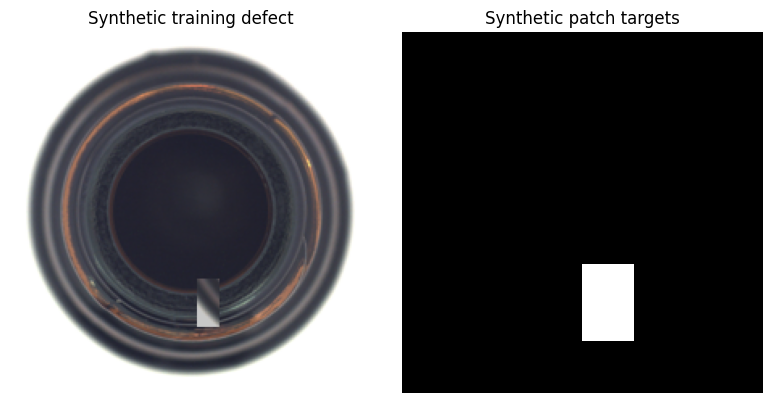

In [4]:
def make_backbone(pretrained=True):
    return timm.create_model(MODEL_NAME, pretrained=pretrained, num_classes=0)

probe_model = make_backbone()
data_config = timm.data.resolve_model_data_config(probe_model)
MEAN, STD = tuple(data_config['mean']), tuple(data_config['std'])
(RUN_DIR / 'preprocessing.json').write_text(json.dumps({
    'mean': MEAN, 'std': STD, 'resize': [IMAGE_SIZE, IMAGE_SIZE],
    'interpolation': 'bicubic', 'crop': False}, indent=2))
preprocess = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BICUBIC),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])
# Preserve initial weights once. Every experiment starts from this same checkpoint.
INITIAL = {k:v.detach().cpu().clone() for k,v in probe_model.state_dict().items()}
torch.save(INITIAL, RUN_DIR / 'initial_backbone.pt')
del probe_model

def fresh_backbone():
    model = make_backbone(pretrained=False)
    model.load_state_dict(INITIAL)
    return model

def patch_tokens(backbone, x):
    tokens = backbone.forward_features(x)
    tokens = tokens[:, backbone.num_prefix_tokens:, :]
    assert tokens.shape[1] == (IMAGE_SIZE // PATCH_SIZE)**2
    return tokens

class ImageDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)
    def __len__(self): return len(self.frame)
    def __getitem__(self, i):
        with Image.open(self.frame.iloc[i].image_path) as image:
            return preprocess(image.convert('RGB'))

def image_loader(frame):
    return DataLoader(ImageDataset(frame), batch_size=BATCH_SIZE,
                      shuffle=False, num_workers=0, pin_memory=AMP)

def paste_defect(image, rng):
    # Adapted CutPaste-style augmentation; not the original paper's exact recipe.
    image = image.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BICUBIC)
    w, h = image.size
    pw, ph = rng.randint(12, 56), rng.randint(12, 56)
    sx, sy = rng.randint(0, w-pw), rng.randint(0, h-ph)
    patch = image.crop((sx, sy, sx+pw, sy+ph))
    patch = patch.rotate(180)
    factor = rng.choice([rng.uniform(0.5, 0.8), rng.uniform(1.2, 1.5)])
    patch = ImageEnhance.Brightness(patch).enhance(factor)
    dx, dy = rng.randint(0, w-pw), rng.randint(0, h-ph)
    out = image.copy()
    out.paste(patch, (dx, dy))
    mask = np.zeros((h, w), dtype=np.float32)
    mask[dy:dy+ph, dx:dx+pw] = 1
    return out, mask

class SyntheticDataset(Dataset):
    def __init__(self, frame, fixed=False, seed=42):
        self.frame = frame.reset_index(drop=True)
        self.fixed, self.seed = fixed, seed
    def __len__(self): return 2 * len(self.frame)
    def __getitem__(self, i):
        with Image.open(self.frame.iloc[i//2].image_path) as source:
            image = source.convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BICUBIC)
        mask = np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.float32)
        rng = random.Random(self.seed+i) if self.fixed else random
        if i % 2:
            image, mask = paste_defect(image, rng)
        # Mark a patch positive if any synthetic-defect pixel intersects it.
        target = F.max_pool2d(torch.from_numpy(mask)[None, None], PATCH_SIZE).flatten()
        return preprocess(image), target

class AdaptationModel(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone
        self.head = nn.Linear(backbone.num_features, 1)
        self.backbone.requires_grad_(False)
        for block in self.backbone.blocks[-2:]:
            block.requires_grad_(True)
        self.backbone.norm.requires_grad_(True)
    def train(self, mode=True):
        super().train(mode)
        # Keep frozen blocks deterministic, train only the selected modules.
        self.backbone.eval()
        for block in self.backbone.blocks[-2:]: block.train(mode)
        self.backbone.norm.train(mode)
        self.head.train(mode)
        return self
    def forward(self, x):
        return self.head(patch_tokens(self.backbone, x)).squeeze(-1)

example_ds = SyntheticDataset(reference_df, fixed=True)
x, target = example_ds[1]
fig, axes = plt.subplots(1,2,figsize=(8,4))
shown = (x.permute(1,2,0).numpy()*np.array(STD)+np.array(MEAN)).clip(0,1)
axes[0].imshow(shown); axes[0].set_title('Synthetic training defect')
axes[1].imshow(target.reshape(14,14), cmap='gray'); axes[1].set_title('Synthetic patch targets')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.savefig(RUN_DIR/'synthetic_example.png', dpi=160); plt.show()


## 3. Fine-tune, validate and select checkpoints (no real test evaluation)
Train a separate category-specific adaptation for bottles and cables. Weighted binary cross-entropy addresses the small number of synthetic positive patches; its fixed positive weight is 5. Fine-tune for at most 12 epochs with early stopping (patience 3), AdamW, cosine LR decay, gradient clipping, and mixed precision on GPU.

Two predeclared learning rates are tried. Validation images receive deterministic synthetic defects, so epoch/configuration comparisons see identical examples. Save every trial's best checkpoint and loss history. Completed trials are reused on rerun; an interrupted trial restarts from the initial checkpoint. Do not tune against real test accuracy. The frozen baseline has no gradient training; it is fitted by storing normal patch features in the next section.


Reusing completed trial: bottle_lr1e-05
Reusing completed trial: bottle_lr3e-05
Reusing completed trial: cable_lr1e-05
Reusing completed trial: cable_lr3e-05


,category,lr,best_epoch,selection_loss,training_seconds,checkpoint
0,bottle,0.00001,12,0.078966,190.284467,/content/drive/MyDrive/Manufacturing_Defects/e...
1,bottle,0.00003,12,0.043701,183.857881,/content/drive/MyDrive/Manufacturing_Defects/e...
2,cable,0.00001,12,0.138755,303.660322,/content/drive/MyDrive/Manufacturing_Defects/e...
3,cable,0.00003,12,0.097646,302.767702,/content/drive/MyDrive/Manufacturing_Defects/e...


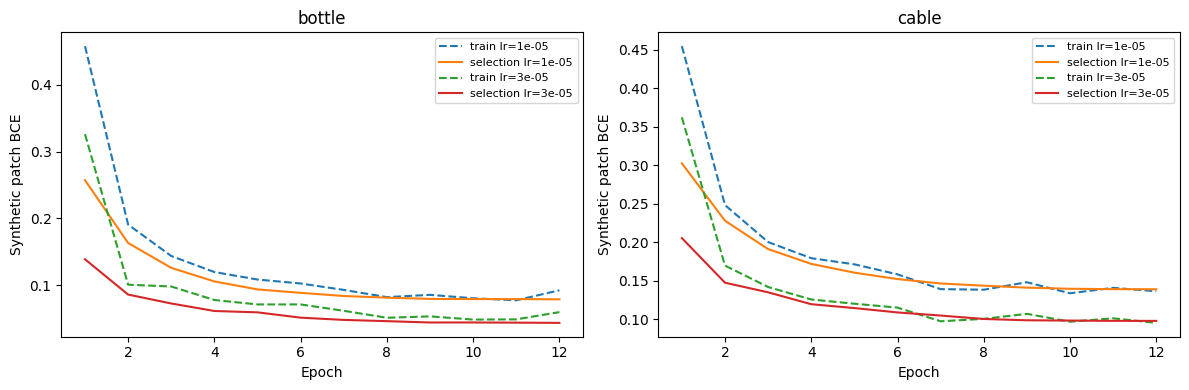

In [5]:
def fit_trial(category, lr):
    seed_everything(SEED)  # identical initial head and augmentation sequence across trials
    tag = f'{category}_lr{lr:g}'
    trial_dir = RUN_DIR / tag
    trial_dir.mkdir(exist_ok=True)
    if (trial_dir/'trial.json').exists() and (trial_dir/'best.pt').exists():
        print('Reusing completed trial:', tag)
        return json.loads((trial_dir/'trial.json').read_text())
    train_frame = reference_df[reference_df.category == category]
    val_frame = selection_df[selection_df.category == category]
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(SyntheticDataset(train_frame), batch_size=BATCH_SIZE,
                              shuffle=True, num_workers=0, generator=generator)
    val_loader = DataLoader(SyntheticDataset(val_frame, fixed=True, seed=10000+SEED),
                            batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    model = AdaptationModel(fresh_backbone()).to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    print(tag, 'trainable parameters:', sum(p.numel() for p in params))
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(5.0, device=DEVICE))
    best, stale, best_epoch = float('inf'), 0, 0
    history = []
    start = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS+1):
        model.train()
        total, n = 0.0, 0
        for x,y in train_loader:
            x,y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=AMP):
                loss = criterion(model(x), y)
            assert torch.isfinite(loss), 'Non-finite training loss'
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(optimizer); scaler.update()
            total += loss.item()*len(x); n += len(x)
        model.eval()
        val_total, val_n = 0.0, 0
        with torch.no_grad():
            for x,y in val_loader:
                x,y = x.to(DEVICE), y.to(DEVICE)
                with torch.autocast(device_type=DEVICE.type, enabled=AMP):
                    val_loss = criterion(model(x), y)
                val_total += val_loss.item()*len(x); val_n += len(x)
        vl = val_total / val_n
        assert math.isfinite(vl), 'Non-finite validation loss'
        history.append(dict(epoch=epoch, train_loss=total/n, selection_loss=vl,
                            lr=optimizer.param_groups[0]['lr']))
        print(f'{tag} epoch {epoch:02d}: train={total/n:.4f}, selection={vl:.4f}')
        if vl < best - 1e-5:
            best, stale, best_epoch = vl, 0, epoch
            torch.save({k:v.detach().cpu() for k,v in model.state_dict().items()},
                       trial_dir / 'best.pt')
        else:
            stale += 1
        pd.DataFrame(history).to_csv(trial_dir/'history.csv', index=False)
        scheduler.step()
        if stale >= PATIENCE: break
    if AMP: torch.cuda.synchronize()
    result = dict(category=category, lr=lr, best_epoch=best_epoch,
                  selection_loss=best, training_seconds=time.perf_counter()-start,
                  checkpoint=str(trial_dir/'best.pt'))
    (trial_dir/'trial.json').write_text(json.dumps(result, indent=2))
    del model, optimizer, scaler
    gc.collect()
    if AMP: torch.cuda.empty_cache()
    return result

trials = []
for category in CATEGORIES:
    for lr in LEARNING_RATES:
        trials.append(fit_trial(category, lr))
trials_df = pd.DataFrame(trials)
trials_df.to_csv(RUN_DIR/'trials.csv', index=False)
selected = {}
for category in CATEGORIES:
    row = trials_df[trials_df.category == category].sort_values('selection_loss').iloc[0]
    selected[category] = str(row.checkpoint)
(RUN_DIR/'selected_checkpoints.json').write_text(json.dumps(selected, indent=2))
display(trials_df)

fig, axes = plt.subplots(1,len(CATEGORIES),figsize=(12,4),squeeze=False)
for ax,category in zip(axes.flat,CATEGORIES):
    for lr in LEARNING_RATES:
        history = pd.read_csv(RUN_DIR/f'{category}_lr{lr:g}'/'history.csv')
        ax.plot(history.epoch,history.train_loss,'--',label=f'train lr={lr:g}')
        ax.plot(history.epoch,history.selection_loss,label=f'selection lr={lr:g}')
    ax.set(title=category, xlabel='Epoch', ylabel='Synthetic patch BCE')
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(RUN_DIR/'learning_curves.png',dpi=160); plt.show()


## 4. Fit the identical nearest-neighbour detector and calibrate thresholds
A reference bank stores up to 10,000 patch vectors sampled uniformly from NORMAL reference images. This is random subsampling, not PatchCore's coreset algorithm. Both methods use exactly the same patch indices. For a new patch, its score is `1 − maximum cosine similarity` to any reference patch. The image score is the maximum of its 196 patch scores. Scores are distances, not probabilities.

The auxiliary synthetic classifier is discarded: its role was to adapt the representation. This keeps the final detector identical and isolates the effect of representation adaptation. The maximum aggregator is sensitive to a single unusual patch; there is no test-driven adjustment of it.


In [6]:
@torch.inference_mode()
def extract_features(backbone, frame):
    backbone.eval()
    chunks = []
    for x in image_loader(frame):
        with torch.autocast(device_type=DEVICE.type, enabled=AMP):
            z = patch_tokens(backbone, x.to(DEVICE))
        chunks.append(F.normalize(z.float(), dim=-1).cpu())
    return torch.cat(chunks)  # images, 196 patches, 384 dimensions

@torch.inference_mode()
def nearest_scores(features, bank):
    bank = F.normalize(bank.to(DEVICE).float(), dim=-1)
    shape = features.shape[:2]
    flat = features.reshape(-1, features.shape[-1])
    distances = []
    # Limit temporary similarity matrices; no full test-by-bank matrix in RAM.
    for q in flat.split(512):
        q = F.normalize(q.to(DEVICE).float(), dim=-1)
        similarity = q @ bank.T
        distances.append((1-similarity.max(dim=1).values).clamp(0,2).cpu())
    maps = torch.cat(distances).reshape(*shape).numpy()
    return maps.max(axis=1), maps.reshape(-1,14,14)

def load_backbone(category, method):
    if method == 'frozen':
        backbone = fresh_backbone()
    else:
        wrapper = AdaptationModel(fresh_backbone())
        wrapper.load_state_dict(torch.load(selected[category], map_location='cpu', weights_only=True))
        backbone = wrapper.backbone
    return backbone.to(DEVICE).eval()

METHODS = ['frozen', 'adapted']
calibration_records = []
for category in CATEGORIES:
    ref = reference_df[reference_df.category == category].reset_index(drop=True)
    cal = calibration_df[calibration_df.category == category].reset_index(drop=True)
    n_patches = len(ref)*196
    indices = np.random.default_rng(SEED).choice(
        n_patches, size=min(MAX_BANK_PATCHES,n_patches), replace=False)
    np.save(RUN_DIR/f'{category}_bank_indices.npy',indices)
    for method in METHODS:
        backbone = load_backbone(category, method)
        ref_features = extract_features(backbone,ref)
        bank = ref_features.reshape(-1,ref_features.shape[-1])[indices].contiguous()
        torch.save(bank,RUN_DIR/f'{category}_{method}_bank.pt')
        cal_features = extract_features(backbone,cal)
        scores,_ = nearest_scores(cal_features,bank)
        threshold = float(np.quantile(scores,1-TARGET_FPR,method='higher'))
        record = dict(category=category,method=method,threshold=threshold,
                      n_calibration=len(cal),calibration_fpr=float((scores>threshold).mean()))
        calibration_records.append(record)
        cal_out = cal[['relative_path']].copy()
        cal_out['score'] = scores
        cal_out.to_csv(RUN_DIR/f'{category}_{method}_calibration.csv',index=False)
        del backbone,ref_features,cal_features,bank
        gc.collect()
        if AMP: torch.cuda.empty_cache()
thresholds_df = pd.DataFrame(calibration_records)
thresholds_df.to_csv(RUN_DIR/'thresholds.csv',index=False)
display(thresholds_df)
print('Model settings, checkpoints and thresholds are now fixed. Proceed to final evaluation.')


,category,method,threshold,n_calibration,calibration_fpr
0,bottle,frozen,0.184741,21,0.047619
1,bottle,adapted,0.225461,21,0.047619
2,cable,frozen,0.360832,23,0.043478
3,cable,adapted,0.367104,23,0.043478


Model settings, checkpoints and thresholds are now fixed. Proceed to final evaluation.


## 5. Final test evaluation
The next cell is the first use of real test labels for model evaluation. Record both methods, even if adaptation loses. Positive label = defective. Report per-category scores and their unweighted category mean; raw anomaly scores from separate banks should not be pooled for a global AUROC.

AUROC and average precision are threshold-free; precision/recall/F1 and false-positive rate use the previously fixed normal-calibration threshold. Stratified bootstrap CIs quantify test-image sampling uncertainty, not training-seed variance or deployment reliability. AP depends on class prevalence.


In [7]:
def bootstrap_auc(y, scores, n_boot=500):
    y, scores = np.asarray(y), np.asarray(scores)
    pos, neg = np.flatnonzero(y==1), np.flatnonzero(y==0)
    if len(pos)==0 or len(neg)==0: return np.nan,np.nan
    rng = np.random.default_rng(SEED)
    values = []
    for _ in range(n_boot):
        idx = np.r_[rng.choice(pos,len(pos),replace=True),rng.choice(neg,len(neg),replace=True)]
        values.append(roc_auc_score(y[idx],scores[idx]))
    return tuple(np.quantile(values,[0.025,0.975]))

metric_rows, prediction_frames = [], []
for category in CATEGORIES:
    frame = test_df[test_df.category == category].reset_index(drop=True)
    y = frame.is_anomaly.to_numpy(dtype=int)
    assert set(y)=={0,1}, 'Both normal and defective test images required.'
    for method in METHODS:
        backbone = load_backbone(category,method)
        bank = torch.load(RUN_DIR/f'{category}_{method}_bank.pt',map_location='cpu',weights_only=True)
        if AMP: torch.cuda.synchronize()
        start = time.perf_counter()
        features = extract_features(backbone,frame)
        scores,maps = nearest_scores(features,bank)
        if AMP: torch.cuda.synchronize()
        elapsed = time.perf_counter()-start
        threshold = float(thresholds_df.query('category == @category and method == @method').threshold.iloc[0])
        pred = (scores>threshold).astype(int)
        tn,fp,fn,tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
        low,high = bootstrap_auc(y,scores)
        metric_rows.append(dict(category=category,method=method,
            auroc=roc_auc_score(y,scores),auc_ci_low=low,auc_ci_high=high,
            average_precision=average_precision_score(y,scores),
            precision=precision_score(y,pred,zero_division=0),
            recall=recall_score(y,pred,zero_division=0),f1=f1_score(y,pred,zero_division=0),
            accuracy=accuracy_score(y,pred),balanced_accuracy=balanced_accuracy_score(y,pred),
            false_positive_rate=fp/(fp+tn),tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp),
            threshold=threshold,seconds_per_image=elapsed/len(frame)))
        out = frame[['relative_path','category','defect_type','is_anomaly']].copy()
        out['method'],out['score'],out['prediction'] = method,scores,pred
        out['threshold'] = threshold
        prediction_frames.append(out)
        np.savez_compressed(RUN_DIR/f'{category}_{method}_test_maps.npz',
                            maps=maps,relative_paths=frame.relative_path.to_numpy(dtype=str))
        del backbone,features,bank
        gc.collect()
        if AMP: torch.cuda.empty_cache()
results = pd.DataFrame(metric_rows)
predictions = pd.concat(prediction_frames,ignore_index=True)
results.to_csv(RUN_DIR/'test_metrics.csv',index=False)
predictions.to_csv(RUN_DIR/'test_predictions.csv',index=False)
display(results.round(4))
macro = results.groupby('method')[['auroc','average_precision','recall','f1','false_positive_rate']].mean()
macro.to_csv(RUN_DIR/'category_macro_metrics.csv')
print('Unweighted mean across the two categories (not pooled AUROC):')
display(macro.round(4))
print('Timing includes image loading, feature extraction and matching; it is not pure model latency.')


,category,method,auroc,auc_ci_low,auc_ci_high,average_precision,precision,recall,f1,accuracy,balanced_accuracy,false_positive_rate,tn,fp,fn,tp,threshold,seconds_per_image
0,bottle,frozen,0.9992,0.9952,1.0000,0.9998,0.9844,1.0000,0.9921,0.9880,0.9750,0.0500,19,1,0,63,0.1847,0.0361
1,bottle,adapted,1.0000,1.0000,1.0000,1.0000,0.9545,1.0000,0.9767,0.9639,0.9250,0.1500,17,3,0,63,0.2255,0.0675
2,cable,frozen,0.8902,0.8363,0.9343,0.9361,0.9492,0.6087,0.7417,0.7400,0.7785,0.0517,55,3,36,56,0.3608,0.0621
3,cable,adapted,0.9378,0.8992,0.9672,0.9649,0.9577,0.7391,0.8344,0.8200,0.8437,0.0517,55,3,24,68,0.3671,0.0531


Unweighted mean across the two categories (not pooled AUROC):


,auroc,average_precision,recall,f1,false_positive_rate
method,,,,,
adapted,0.9689,0.9825,0.8696,0.9056,0.1009
frozen,0.9447,0.9679,0.8043,0.8669,0.0509


Timing includes image loading, feature extraction and matching; it is not pure model latency.


## 6. Curves, confusion matrices, per-defect recall and paired comparison
Per-defect recall shows what aggregate scores hide. Small test subgroups are uncertain: report their sample counts. Paired bootstrap uses the SAME sampled test images for both methods, the difference is adapted minus frozen.


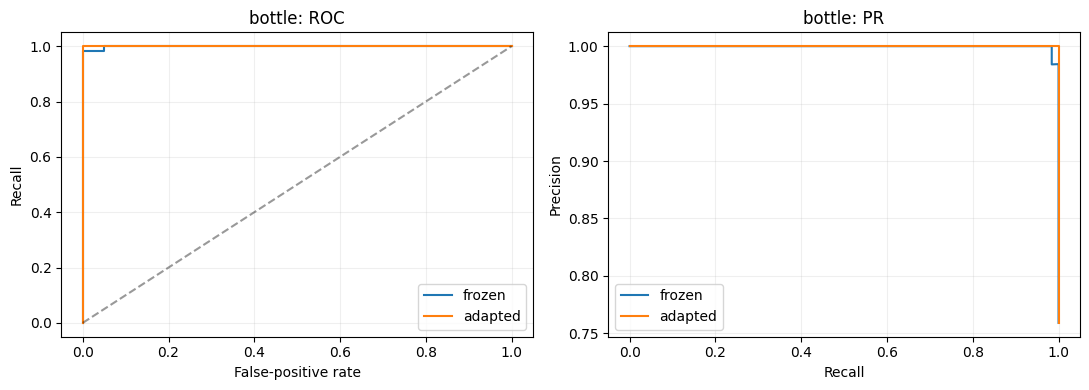

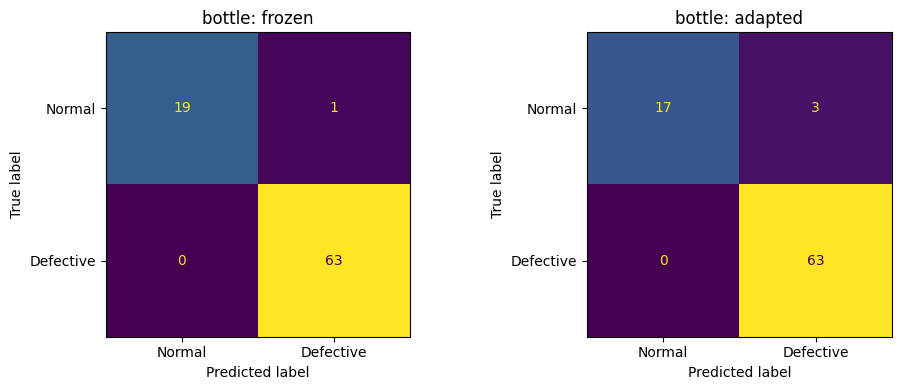

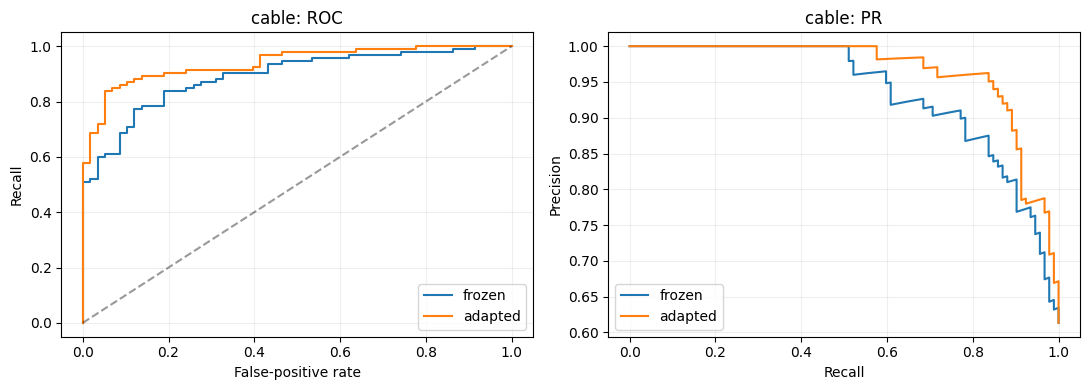

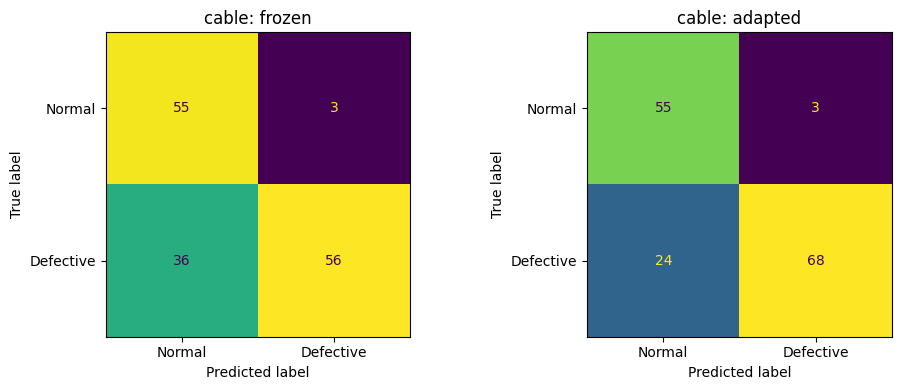

,category,method,defect_type,count,detected,recall
0,bottle,adapted,broken_large,20,20,1.000000
1,bottle,adapted,broken_small,22,22,1.000000
2,bottle,adapted,contamination,21,21,1.000000
3,bottle,frozen,broken_large,20,20,1.000000
4,bottle,frozen,broken_small,22,22,1.000000
5,bottle,frozen,contamination,21,21,1.000000
6,cable,adapted,bent_wire,13,13,1.000000
7,cable,adapted,cable_swap,12,2,0.166667
8,cable,adapted,combined,11,10,0.909091
9,cable,adapted,cut_inner_insulation,14,11,0.785714


,category,auroc_change,ci_low,ci_high
0,bottle,0.000794,0.000000,0.004762
1,cable,0.047601,0.010022,0.089154


In [8]:
for category in CATEGORIES:
    fig,axes = plt.subplots(1,2,figsize=(11,4))
    for method in METHODS:
        p = predictions[(predictions.category==category)&(predictions.method==method)]
        fpr,tpr,_ = roc_curve(p.is_anomaly,p.score)
        precision,recall,_ = precision_recall_curve(p.is_anomaly,p.score)
        axes[0].plot(fpr,tpr,label=method)
        axes[1].plot(recall,precision,label=method)
    axes[0].plot([0,1],[0,1],'k--',alpha=.4)
    axes[0].set(xlabel='False-positive rate',ylabel='Recall',title=f'{category}: ROC')
    axes[1].set(xlabel='Recall',ylabel='Precision',title=f'{category}: PR')
    for ax in axes: ax.legend(); ax.grid(alpha=.2)
    plt.tight_layout(); plt.savefig(RUN_DIR/f'{category}_curves.png',dpi=160); plt.show()
    fig,axes = plt.subplots(1,2,figsize=(10,4))
    for ax,method in zip(axes,METHODS):
        p = predictions[(predictions.category==category)&(predictions.method==method)]
        ConfusionMatrixDisplay(confusion_matrix(p.is_anomaly,p.prediction,labels=[0,1]),
                               display_labels=['Normal','Defective']).plot(ax=ax,colorbar=False)
        ax.set_title(f'{category}: {method}')
    plt.tight_layout(); plt.savefig(RUN_DIR/f'{category}_confusion.png',dpi=160); plt.show()

per_defect = (predictions[predictions.is_anomaly==1]
    .groupby(['category','method','defect_type']).prediction.agg(['count','sum','mean'])
    .rename(columns={'sum':'detected','mean':'recall'}).reset_index())
per_defect.to_csv(RUN_DIR/'per_defect_recall.csv',index=False)
display(per_defect)

def paired_auc_difference(y,a,b,n_boot=500):
    y,a,b = np.asarray(y),np.asarray(a),np.asarray(b)
    pos,neg = np.flatnonzero(y==1),np.flatnonzero(y==0)
    rng = np.random.default_rng(SEED)
    values = []
    for _ in range(n_boot):
        idx=np.r_[rng.choice(pos,len(pos),replace=True),rng.choice(neg,len(neg),replace=True)]
        values.append(roc_auc_score(y[idx],b[idx])-roc_auc_score(y[idx],a[idx]))
    return float(roc_auc_score(y,b)-roc_auc_score(y,a)),*np.quantile(values,[.025,.975])

differences=[]
for category in CATEGORIES:
    a=predictions.query('category == @category and method == "frozen"')
    b=predictions.query('category == @category and method == "adapted"')
    paired=a.merge(b,on='relative_path',suffixes=('_frozen','_adapted'),validate='one_to_one')
    delta,low,high=paired_auc_difference(paired.is_anomaly_frozen,paired.score_frozen,paired.score_adapted)
    differences.append(dict(category=category,auroc_change=delta,ci_low=low,ci_high=high))
differences=pd.DataFrame(differences)
differences.to_csv(RUN_DIR/'paired_auroc_difference.csv',index=False)
display(differences)


## 6b. Deeper analysis: where the scores separate, which defects are hard, and why
Aggregate metrics can hide very different behaviour across defect types. This section uses only the saved test predictions and the ground-truth masks (for analysis, never for fitting) to answer four questions:

1. **Score distributions** - How far apart are normal and defective scores, per defect type, relative to the fixed threshold?
2. **Per-defect AUROC** - A threshold-free measure of how well each defect type is separated from normal test images. Recall depends on the single chosen threshold; AUROC does not.
3. **Defect size** - Are small defects (by ground-truth mask area at the original resolution) harder to detect after resizing to 224×224?
4. **Realistic prevalence** - The test split is defect-heavy (≈76% of bottle and ≈61% of cable test images are defective). Real production lines usually have far fewer defects, so test-set precision overstates what an operator would see. We recompute precision for plausible defect rates using the measured recall and false-positive rate.

Per-defect groups contain only 10–22 images, so per-defect numbers are indicative, not precise.

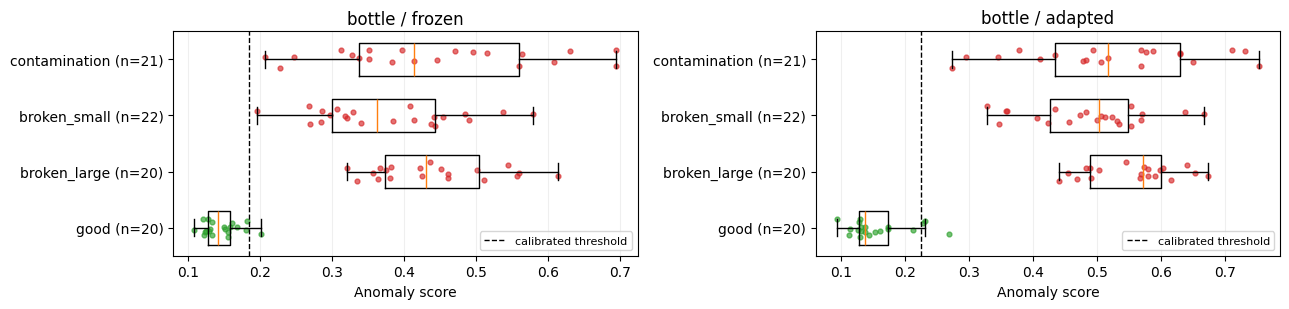

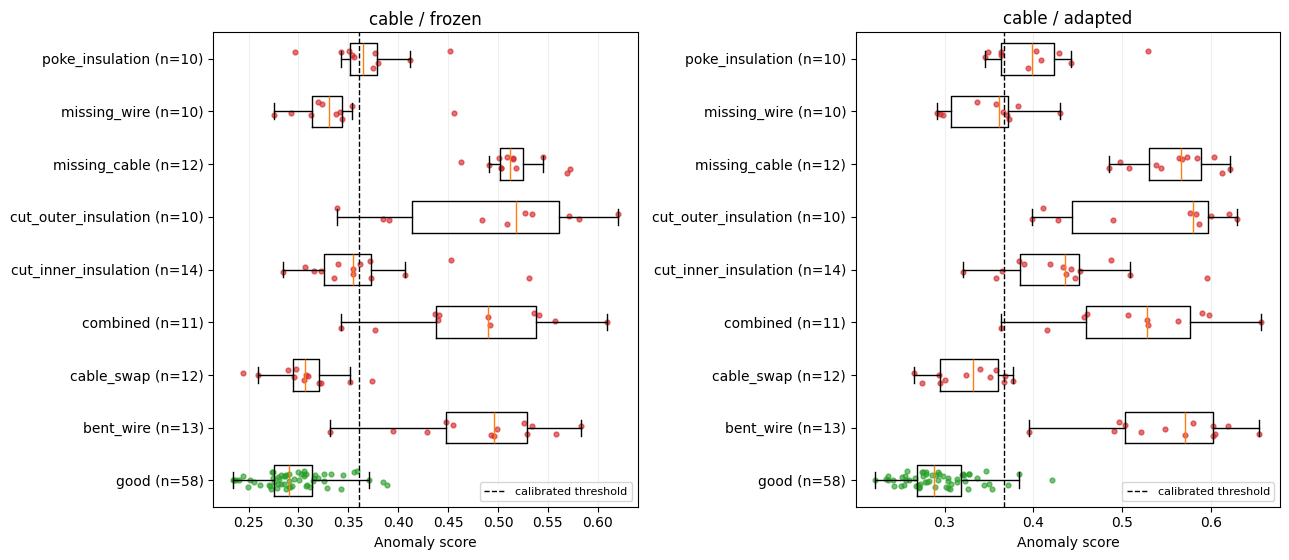

Scores are distances on method-specific scales: compare each panel with its own threshold, not the raw values across panels.


auroc        recall_at_threshold  \
method                                    adapted frozen             adapted   
category defect_type          n_defective                                      
bottle   broken_large         20            1.000  1.000               1.000   
         broken_small         22            1.000  0.998               1.000   
         contamination        21            1.000  1.000               1.000   
cable    bent_wire            13            0.999  0.989               1.000   
         cable_swap           12            0.733  0.618               0.167   
         combined             11            0.994  0.986               0.909   
         cut_inner_insulation 14            0.972  0.863               0.786   
         cut_outer_insulation 10            0.997  0.986               1.000   
         missing_cable        12            1.000  1.000               1.000   
         missing_wire         10            0.834  0.772               0.400   
         poke_insulation      10            0.966  0.910               0.600   

                                                  
method                                    frozen  
category defect_type          n_defective         
bottle   broken_large         20           1.000  
         broken_small         22           1.000  
         contamination        21           1.000  
cable    bent_wire            13           0.923  
         cable_swap           12           0.083  
         combined             11           0.909  
         cut_inner_insulation 14           0.429  
         cut_outer_insulation 10           0.900  
         missing_cable        12           1.000  
         missing_wire         10           0.100  
         poke_insulation      10           0.500

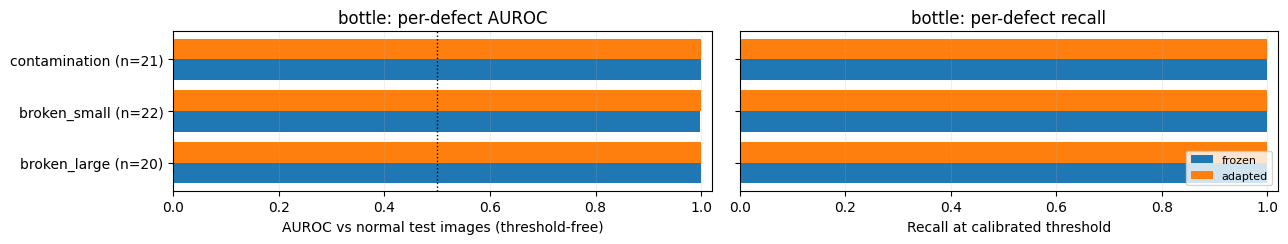

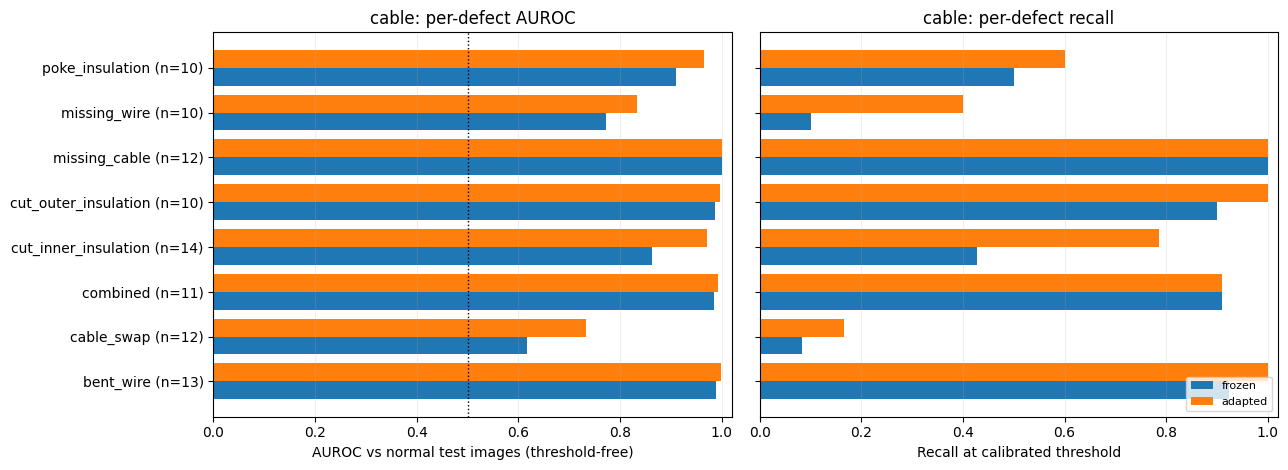

Mask areas:   0%|          | 0/155 [00:00<?, ?it/s]

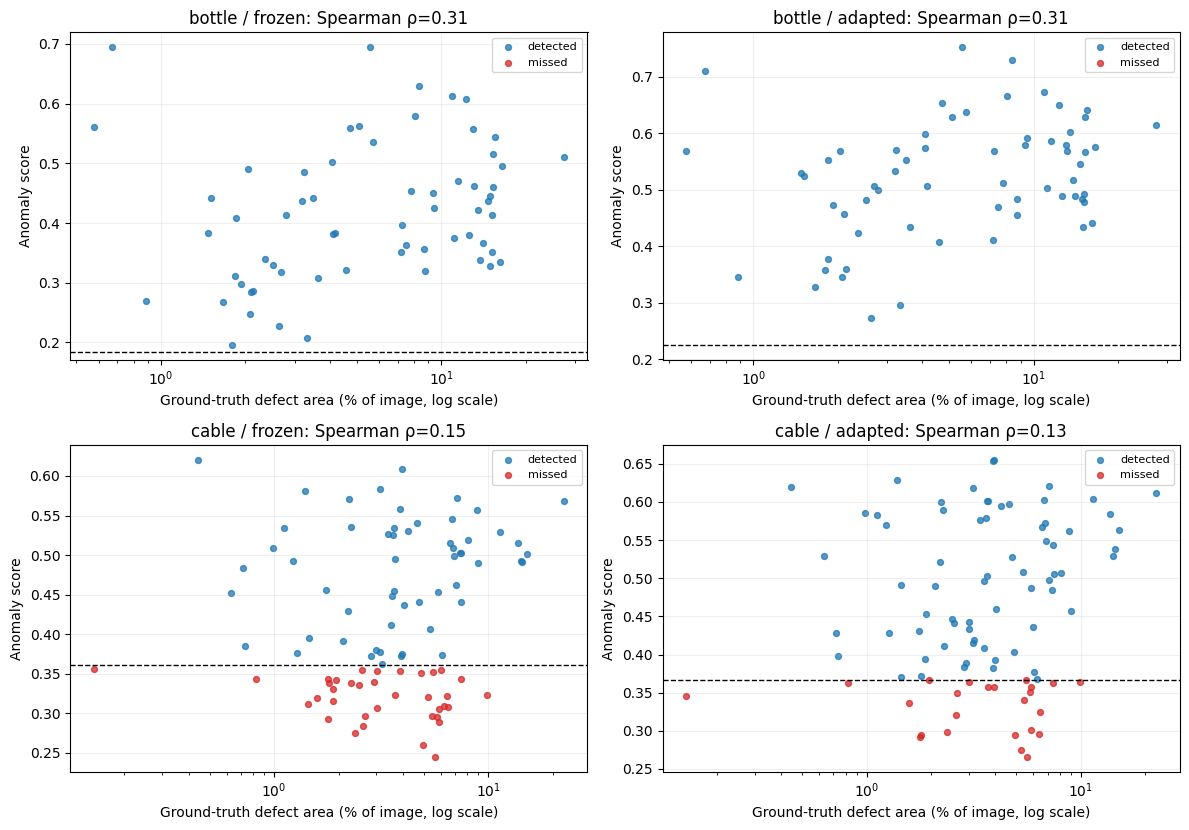

Recall by defect-size tertile (the spearman_rho rows store ρ in the recall column):


,category,method,size_bin,n,area_range,recall
0,bottle,frozen,small,21,0.58–3.24%,1.000
1,bottle,frozen,medium,21,3.33–9.46%,1.000
2,bottle,frozen,large,21,10.89–27.42%,1.000
3,bottle,frozen,spearman_rho,63,p=0.012,0.314
4,bottle,adapted,small,21,0.58–3.24%,1.000
5,bottle,adapted,medium,21,3.33–9.46%,1.000
6,bottle,adapted,large,21,10.89–27.42%,1.000
7,bottle,adapted,spearman_rho,63,p=0.014,0.308
8,cable,frozen,small,31,0.14–2.65%,0.484
9,cable,frozen,medium,30,2.84–5.45%,0.700


At 224×224 input, one ViT patch covers ≈73×73 original cable pixels and ≈64×64 original bottle pixels.


,category,method,recall,false_positive_rate,n_test_normals,test_prevalence,precision_on_test,false_alarms_per_1000_good_parts,precision_at_5.0%_defects,precision_at_1.0%_defects,precision_at_0.5%_defects
0,bottle,frozen,1.000,0.050,20,0.759,0.984,50.000,0.513,0.168,0.091
1,bottle,adapted,1.000,0.150,20,0.759,0.955,150.000,0.260,0.063,0.032
2,cable,frozen,0.609,0.052,58,0.613,0.949,51.724,0.382,0.106,0.056
3,cable,adapted,0.739,0.052,58,0.613,0.958,51.724,0.429,0.126,0.067


False-positive rates are estimated from only 20 (bottle) and 58 (cable) normal test images, so these projections are rough. They show why test-set precision should not be quoted as field performance.


In [9]:
from scipy.stats import spearmanr

# ---------- 1. Score distributions per defect type ----------
def plot_score_distributions(preds, methods, filename):
    for category in CATEGORIES:
        sub = preds[preds.category == category]
        order = ['good'] + sorted(t for t in sub.defect_type.unique() if t != 'good')
        fig, axes = plt.subplots(1, len(methods), figsize=(6.5 * len(methods), 1.2 + 0.5 * len(order)),
                                 squeeze=False)
        for ax, method in zip(axes.flat, methods):
            p = sub[sub.method == method]
            data = [p.loc[p.defect_type == t, 'score'].to_numpy() for t in order]
            try:  # Matplotlib >= 3.10
                ax.boxplot(data, orientation='horizontal', showfliers=False, widths=0.6)
            except TypeError:  # older Matplotlib
                ax.boxplot(data, vert=False, showfliers=False, widths=0.6)
            for i, d in enumerate(data, start=1):
                jitter = np.random.default_rng(i).uniform(-0.18, 0.18, len(d))
                ax.scatter(d, i + jitter, s=12, alpha=0.65,
                           color='tab:green' if order[i - 1] == 'good' else 'tab:red')
            ax.axvline(p.threshold.iloc[0], color='k', ls='--', lw=1, label='calibrated threshold')
            ax.set_yticks(range(1, len(order) + 1))
            ax.set_yticklabels([f'{t} (n={len(d)})' for t, d in zip(order, data)])
            ax.set(title=f'{category} / {method}', xlabel='Anomaly score')
            ax.legend(loc='lower right', fontsize=8)
            ax.grid(axis='x', alpha=.2)
        plt.tight_layout()
        plt.savefig(RUN_DIR / f'{category}_{filename}', dpi=160)
        plt.show()

plot_score_distributions(predictions, METHODS, 'score_distributions.png')
print('Scores are distances on method-specific scales: compare each panel with its own threshold, '
      'not the raw values across panels.')

# ---------- 2. Per-defect AUROC (each defect type vs all normal test images) ----------
def per_defect_table(preds):
    rows = []
    for (category, method), p in preds.groupby(['category', 'method']):
        normal = p.loc[p.is_anomaly == 0, 'score'].to_numpy()
        for defect, d in p[p.is_anomaly == 1].groupby('defect_type'):
            y = np.r_[np.zeros(len(normal)), np.ones(len(d))]
            s = np.r_[normal, d.score.to_numpy()]
            rows.append(dict(category=category, method=method, defect_type=defect,
                             n_defective=len(d), n_normal=len(normal),
                             auroc=roc_auc_score(y, s), recall_at_threshold=d.prediction.mean()))
    return pd.DataFrame(rows)

def plot_per_defect(table, methods, filename):
    colours = dict(zip(methods, plt.cm.tab10.colors))
    for category in CATEGORIES:
        t = table[table.category == category]
        defects = sorted(t.defect_type.unique())
        y = np.arange(len(defects))
        h = 0.8 / len(methods)
        fig, axes = plt.subplots(1, 2, figsize=(13, 1.2 + 0.45 * len(defects) * max(1, len(methods) / 2)),
                                 sharey=True)
        for k, method in enumerate(methods):
            m = t[t.method == method].set_index('defect_type').reindex(defects)
            offset = (k - (len(methods) - 1) / 2) * h
            axes[0].barh(y + offset, m.auroc, height=h, color=colours[method], label=method)
            axes[1].barh(y + offset, m.recall_at_threshold, height=h, color=colours[method], label=method)
        n = t.drop_duplicates('defect_type').set_index('defect_type').reindex(defects).n_defective
        axes[0].set_yticks(y)
        axes[0].set_yticklabels([f'{d} (n={int(c)})' for d, c in zip(defects, n)])
        axes[0].axvline(0.5, color='k', ls=':', lw=1)
        axes[0].set(xlim=(0, 1.02), xlabel='AUROC vs normal test images (threshold-free)',
                    title=f'{category}: per-defect AUROC')
        axes[1].set(xlim=(0, 1.02), xlabel='Recall at calibrated threshold',
                    title=f'{category}: per-defect recall')
        for ax in axes:
            ax.grid(axis='x', alpha=.2)
            ax.invert_yaxis()
        axes[1].legend(loc='lower right', fontsize=8)
        plt.tight_layout()
        plt.savefig(RUN_DIR / f'{category}_{filename}', dpi=160)
        plt.show()

per_defect_auc = per_defect_table(predictions)
per_defect_auc.to_csv(RUN_DIR / 'per_defect_auroc.csv', index=False)
display(per_defect_auc.pivot_table(index=['category', 'defect_type', 'n_defective'],
                                   columns='method', values=['auroc', 'recall_at_threshold']).round(3))
plot_per_defect(per_defect_auc, METHODS, 'per_defect_comparison.png')

# ---------- 3. Defect size vs detectability ----------
def mask_area_percent(relative_path):
    category, _, defect, filename = Path(relative_path).parts
    path = DATA_DIR / category / 'ground_truth' / defect / (Path(filename).stem + '_mask.png')
    with Image.open(path) as mask:
        return float((np.array(mask.convert('L')) > 0).mean() * 100)

defective = predictions[predictions.is_anomaly == 1].copy()
area_lookup = {rp: mask_area_percent(rp) for rp in tqdm(defective.relative_path.unique(), desc='Mask areas')}
defective['defect_area_percent'] = defective.relative_path.map(area_lookup)

fig, axes = plt.subplots(len(CATEGORIES), len(METHODS), figsize=(12, 4.2 * len(CATEGORIES)), squeeze=False)
size_rows = []
for r, category in enumerate(CATEGORIES):
    for c, method in enumerate(METHODS):
        d = defective[(defective.category == category) & (defective.method == method)]
        rho, pval = spearmanr(d.defect_area_percent, d.score)
        ax = axes[r, c]
        for detected, colour, label in [(1, 'tab:blue', 'detected'), (0, 'tab:red', 'missed')]:
            q = d[d.prediction == detected]
            ax.scatter(q.defect_area_percent, q.score, s=18, alpha=.75, color=colour, label=label)
        ax.axhline(d.threshold.iloc[0], color='k', ls='--', lw=1)
        ax.set_xscale('log')
        ax.set(title=f'{category} / {method}: Spearman ρ={rho:.2f}',
               xlabel='Ground-truth defect area (% of image, log scale)', ylabel='Anomaly score')
        ax.legend(fontsize=8)
        ax.grid(alpha=.2)
        d = d.assign(size_bin=pd.qcut(d.defect_area_percent, 3, labels=['small', 'medium', 'large']))
        for size_bin, group in d.groupby('size_bin', observed=True):
            size_rows.append(dict(category=category, method=method, size_bin=str(size_bin), n=len(group),
                                  area_range=f'{group.defect_area_percent.min():.2f}–{group.defect_area_percent.max():.2f}%',
                                  recall=group.prediction.mean()))
        size_rows.append(dict(category=category, method=method, size_bin='spearman_rho', n=len(d),
                              area_range=f'p={pval:.3f}', recall=rho))
plt.tight_layout()
plt.savefig(RUN_DIR / 'defect_size_vs_score.png', dpi=160)
plt.show()
size_table = pd.DataFrame(size_rows)
size_table.to_csv(RUN_DIR / 'recall_by_defect_size.csv', index=False)
print('Recall by defect-size tertile (the spearman_rho rows store ρ in the recall column):')
display(size_table.round(3))
print(f'At 224×224 input, one ViT patch covers ≈{1024 / 14:.0f}×{1024 / 14:.0f} original cable pixels '
      f'and ≈{900 / 14:.0f}×{900 / 14:.0f} original bottle pixels.')

# ---------- 4. Precision at realistic defect rates ----------
prevalence_rows = []
for row in results.itertuples():
    test_prevalence = (row.tp + row.fn) / (row.tp + row.fn + row.tn + row.fp)
    record = dict(category=row.category, method=row.method, recall=row.recall,
                  false_positive_rate=row.false_positive_rate,
                  n_test_normals=row.tn + row.fp, test_prevalence=test_prevalence,
                  precision_on_test=row.precision,
                  false_alarms_per_1000_good_parts=1000 * row.false_positive_rate)
    for prevalence in [0.05, 0.01, 0.005]:
        tp_rate = row.recall * prevalence
        fp_rate = row.false_positive_rate * (1 - prevalence)
        record[f'precision_at_{prevalence:.1%}_defects'] = tp_rate / (tp_rate + fp_rate) if tp_rate + fp_rate else np.nan
    prevalence_rows.append(record)
prevalence_table = pd.DataFrame(prevalence_rows)
prevalence_table.to_csv(RUN_DIR / 'precision_at_realistic_prevalence.csv', index=False)
display(prevalence_table.round(3))
print('False-positive rates are estimated from only 20 (bottle) and 58 (cable) normal test images, '
      'so these projections are rough. They show why test-set precision should not be quoted as field performance.')

## 7. Inspect failures and anomaly heatmaps
Heatmaps show patch distances, not attention weights and not calibrated probabilities. They are coarse 14×14 maps interpolated to 224×224; they do not establish pixel-accurate localisation. Ground-truth masks are shown only for inspection. Use the same colour scale within each method/category, based on calibration threshold (not per-image min/max), to avoid making every image look equally anomalous.

The examples below prioritise false negatives and false positives. If none exist, show near-threshold examples. Do not select only successful images for the report.


In [10]:
def load_ground_truth(relative_path):
    parts=Path(relative_path).parts
    category,_,defect,filename=parts
    if defect=='good': return np.zeros((IMAGE_SIZE,IMAGE_SIZE),dtype=bool)
    path=DATA_DIR/category/'ground_truth'/defect/(Path(filename).stem+'_mask.png')
    assert path.is_file(),f'Missing evaluation mask: {path}'
    with Image.open(path) as mask:
        return np.array(mask.convert('L').resize((IMAGE_SIZE,IMAGE_SIZE),Image.Resampling.NEAREST))>0

for category in CATEGORIES:
    for method in METHODS:
        p=predictions[(predictions.category==category)&(predictions.method==method)].copy()
        errors=p[p.is_anomaly!=p.prediction].copy()
        errors['margin']=(errors.score-errors.threshold).abs()
        if len(errors):
            examples=errors.sort_values('margin',ascending=False).head(4)
        else:
            p['margin']=(p.score-p.threshold).abs()
            examples=p.sort_values('margin').head(4)
        packed=np.load(RUN_DIR/f'{category}_{method}_test_maps.npz')
        map_lookup=dict(zip(packed['relative_paths'].tolist(),packed['maps']))
        fig,axes=plt.subplots(len(examples),3,figsize=(10,3*len(examples)),squeeze=False)
        for row_axes,example in zip(axes,examples.itertuples()):
            with Image.open(DATA_DIR/example.relative_path) as im:
                image=np.array(im.convert('RGB').resize((IMAGE_SIZE,IMAGE_SIZE),Image.Resampling.BICUBIC))
            patch_map=torch.from_numpy(map_lookup[example.relative_path])[None,None]
            heat=F.interpolate(patch_map,size=(IMAGE_SIZE,IMAGE_SIZE),mode='bilinear',align_corners=False)[0,0].numpy()
            mask=load_ground_truth(example.relative_path)
            row_axes[0].imshow(image)
            row_axes[0].set_title(f'{example.defect_type}\ntrue={example.is_anomaly}, predicted={example.prediction}')
            row_axes[1].imshow(image)
            row_axes[1].imshow(heat,cmap='inferno',alpha=.6,vmin=0,vmax=max(example.threshold*1.5,1e-6))
            row_axes[1].set_title(f'score={example.score:.3f}\nthreshold={example.threshold:.3f}')
            row_axes[2].imshow(mask,cmap='gray'); row_axes[2].set_title('Ground truth')
            for ax in row_axes: ax.axis('off')
        fig.suptitle(f'{category} / {method}: errors or near-threshold examples')
        plt.tight_layout(); plt.savefig(RUN_DIR/f'{category}_{method}_error_examples.png',dpi=160); plt.show()


Output hidden; open in https://colab.research.google.com to view.

## 8. Multimodal reference: zero-shot CLIP
The assignment brief allows a ViT or a multimodal model such as CLIP. To show **why** a patch-level ViT detector was chosen as the main method, this section adds a zero-shot CLIP baseline (ViT-B/16 image encoder; Radford et al., 2021) that sees **no** bottle or cable training images.

Each image is compared with two small prompt ensembles, fixed before running this section: "normal" prompts (e.g. *a photo of a flawless bottle*) and "anomalous" prompts (e.g. *a photo of a damaged bottle*). The anomaly score is the softmax probability of the anomalous ensemble, a simplified version of the image-level part of WinCLIP (Jeong et al., 2023). The threshold is set exactly as for the ViT methods: the 95th percentile of scores on the same normal calibration images. No prompts or settings are tuned on test results.

What to expect: CLIP was trained to match whole images to captions, so it tends to recognise obvious, large damage but can miss small or "logical" defects (a correct-looking but wrong arrangement of parts). It is a **reference point**, not a competitor that was given equal tuning effort. If the CLIP checkpoint cannot be downloaded, skip this section; nothing later depends on it except the combined comparison.

config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

...

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

,category,method,auroc,auc_ci_low,auc_ci_high,average_precision,recall,false_positive_rate,f1,tp,fn,fp,tn
1,bottle,adapted,1.000,1.000,1.000,1.000,1.000,0.150,0.977,63,0,3,17
4,bottle,clip_zero_shot,0.940,0.882,0.979,0.982,0.778,0.050,0.867,49,14,1,19
0,bottle,frozen,0.999,0.995,1.000,1.000,1.000,0.050,0.992,63,0,1,19
3,cable,adapted,0.938,0.899,0.967,0.965,0.739,0.052,0.834,68,24,3,55
5,cable,clip_zero_shot,0.752,0.673,0.826,0.799,0.457,0.121,0.596,42,50,7,51
2,cable,frozen,0.890,0.836,0.934,0.936,0.609,0.052,0.742,56,36,3,55


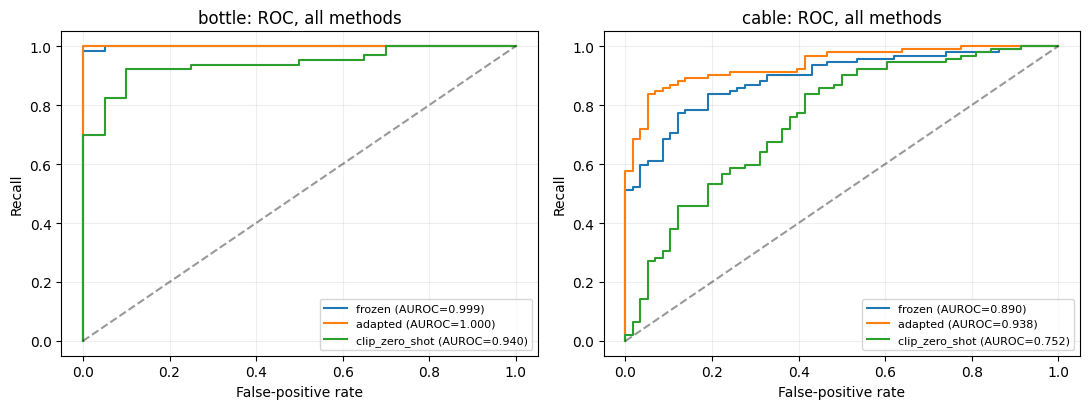

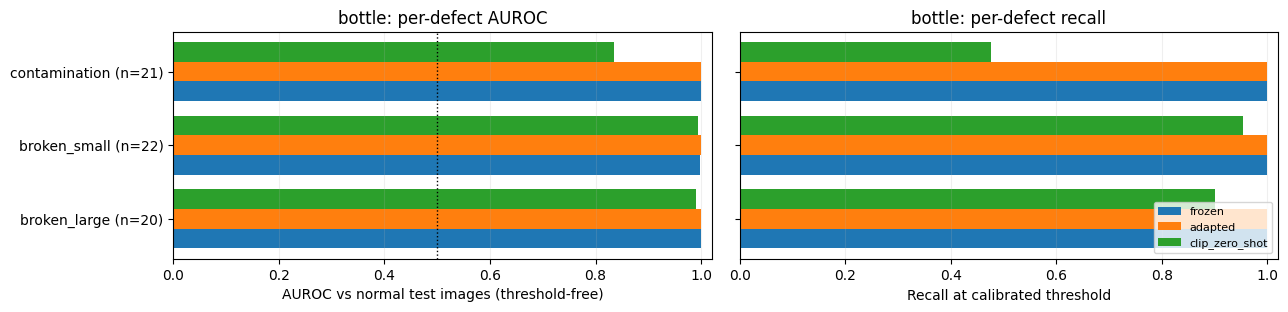

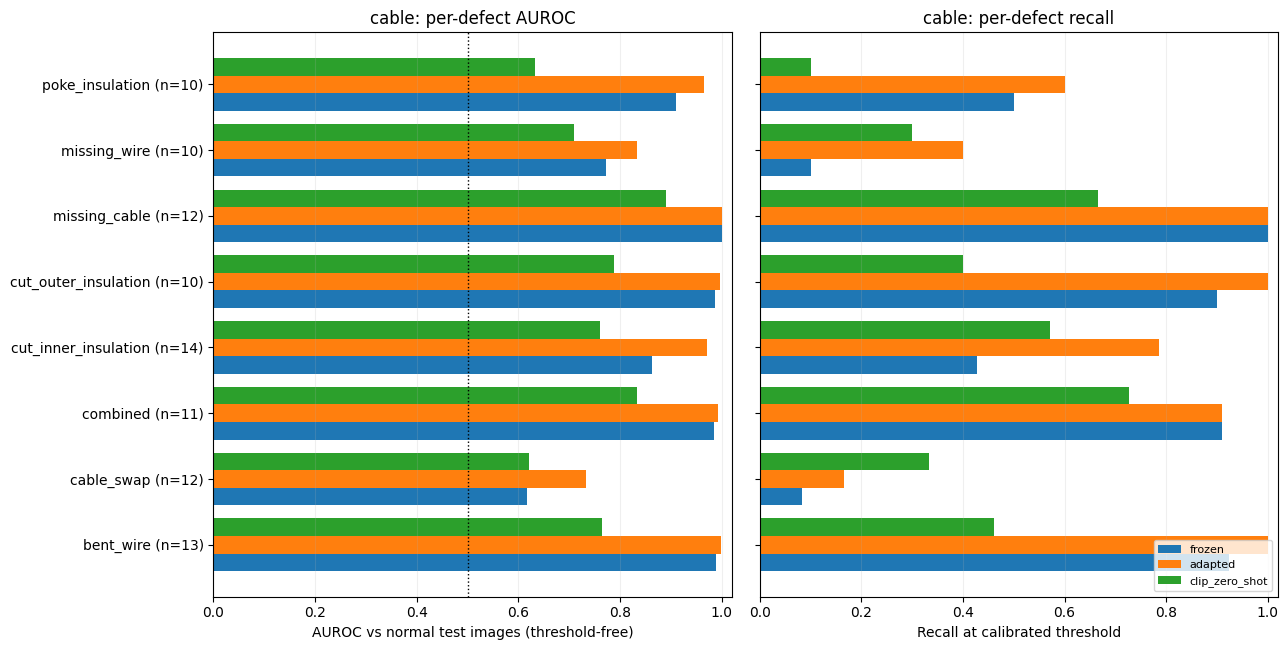

In [11]:
from transformers import CLIPModel, CLIPProcessor

CLIP_NAME = 'openai/clip-vit-base-patch16'
CLIP_DIR = RUN_DIR / 'clip_zero_shot'
CLIP_DIR.mkdir(exist_ok=True)
OBJECT_NAMES = {'bottle': 'bottle', 'cable': 'cable'}
NORMAL_TEMPLATES = ['a photo of a flawless {}.', 'a photo of a perfect {}.',
                    'a photo of an intact {}.', 'a close-up photo of a {} without defects.']
ANOMALY_TEMPLATES = ['a photo of a damaged {}.', 'a photo of a broken {}.',
                     'a photo of a {} with a defect.', 'a close-up photo of a defective {}.']
clip_settings = dict(model=CLIP_NAME, object_names=OBJECT_NAMES, normal_templates=NORMAL_TEMPLATES,
                     anomaly_templates=ANOMALY_TEMPLATES, score='softmax probability of anomaly ensemble',
                     threshold=f'{1 - TARGET_FPR:.0%} quantile of normal calibration scores')
(CLIP_DIR / 'clip_settings.json').write_text(json.dumps(clip_settings, indent=2))

clip_model = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_NAME)

def _embedding(output):
    # transformers 4.x returns a tensor; some newer versions return a model-output object.
    return output if torch.is_tensor(output) else output.pooler_output

@torch.inference_mode()
def clip_text_embeddings(category):
    obj = OBJECT_NAMES[category]
    prototypes = []
    for templates in (NORMAL_TEMPLATES, ANOMALY_TEMPLATES):
        tokens = clip_processor(text=[t.format(obj) for t in templates],
                                return_tensors='pt', padding=True).to(DEVICE)
        e = F.normalize(_embedding(clip_model.get_text_features(**tokens)).float(), dim=-1)
        prototypes.append(F.normalize(e.mean(0), dim=-1))
    return torch.stack(prototypes)  # row 0 = normal, row 1 = anomalous

@torch.inference_mode()
def clip_scores(frame, text_embeddings, batch_size=16):
    scores = []
    paths = frame.image_path.tolist()
    for i in range(0, len(paths), batch_size):
        images = []
        for path in paths[i:i + batch_size]:
            with Image.open(path) as im:
                images.append(im.convert('RGB'))
        pixels = clip_processor(images=images, return_tensors='pt')['pixel_values'].to(DEVICE)
        image_emb = F.normalize(_embedding(clip_model.get_image_features(pixel_values=pixels)).float(), dim=-1)
        logits = clip_model.logit_scale.exp().float() * image_emb @ text_embeddings.T
        scores.append(logits.softmax(dim=-1)[:, 1].cpu())
    return torch.cat(scores).numpy()

clip_metric_rows, clip_prediction_frames, clip_threshold_rows = [], [], []
for category in CATEGORIES:
    text_emb = clip_text_embeddings(category)
    cal = calibration_df[calibration_df.category == category].reset_index(drop=True)
    cal_scores = clip_scores(cal, text_emb)
    threshold = float(np.quantile(cal_scores, 1 - TARGET_FPR, method='higher'))
    clip_threshold_rows.append(dict(category=category, method='clip_zero_shot', threshold=threshold,
                                    n_calibration=len(cal),
                                    calibration_fpr=float((cal_scores > threshold).mean())))
    frame = test_df[test_df.category == category].reset_index(drop=True)
    y = frame.is_anomaly.to_numpy(dtype=int)
    if AMP: torch.cuda.synchronize()
    start = time.perf_counter()
    scores = clip_scores(frame, text_emb)
    if AMP: torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    pred = (scores > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    low, high = bootstrap_auc(y, scores)
    clip_metric_rows.append(dict(category=category, method='clip_zero_shot',
        auroc=roc_auc_score(y, scores), auc_ci_low=low, auc_ci_high=high,
        average_precision=average_precision_score(y, scores),
        precision=precision_score(y, pred, zero_division=0),
        recall=recall_score(y, pred, zero_division=0), f1=f1_score(y, pred, zero_division=0),
        accuracy=accuracy_score(y, pred), balanced_accuracy=balanced_accuracy_score(y, pred),
        false_positive_rate=fp / (fp + tn), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
        threshold=threshold, seconds_per_image=elapsed / len(frame)))
    out = frame[['relative_path', 'category', 'defect_type', 'is_anomaly']].copy()
    out['method'], out['score'], out['prediction'], out['threshold'] = 'clip_zero_shot', scores, pred, threshold
    clip_prediction_frames.append(out)

clip_results = pd.DataFrame(clip_metric_rows)
clip_predictions = pd.concat(clip_prediction_frames, ignore_index=True)
pd.DataFrame(clip_threshold_rows).to_csv(CLIP_DIR / 'thresholds.csv', index=False)
clip_results.to_csv(CLIP_DIR / 'test_metrics.csv', index=False)
clip_predictions.to_csv(CLIP_DIR / 'test_predictions.csv', index=False)
del clip_model
gc.collect()
if AMP: torch.cuda.empty_cache()

# ---------- Combined comparison of all three methods ----------
ALL_METHODS = METHODS + ['clip_zero_shot']
all_results = pd.concat([results, clip_results], ignore_index=True)
all_predictions = pd.concat([predictions, clip_predictions], ignore_index=True)
all_results.to_csv(RUN_DIR / 'all_methods_test_metrics.csv', index=False)
summary_cols = ['category', 'method', 'auroc', 'auc_ci_low', 'auc_ci_high', 'average_precision',
                'recall', 'false_positive_rate', 'f1', 'tp', 'fn', 'fp', 'tn']
display(all_results[summary_cols].sort_values(['category', 'method']).round(3))

fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(11, 4.2), squeeze=False)
for ax, category in zip(axes.flat, CATEGORIES):
    for method in ALL_METHODS:
        p = all_predictions[(all_predictions.category == category) & (all_predictions.method == method)]
        fpr, tpr, _ = roc_curve(p.is_anomaly, p.score)
        auc = roc_auc_score(p.is_anomaly, p.score)
        ax.plot(fpr, tpr, label=f'{method} (AUROC={auc:.3f})')
    ax.plot([0, 1], [0, 1], 'k--', alpha=.4)
    ax.set(xlabel='False-positive rate', ylabel='Recall', title=f'{category}: ROC, all methods')
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(alpha=.2)
plt.tight_layout()
plt.savefig(RUN_DIR / 'roc_all_methods.png', dpi=160)
plt.show()

per_defect_all = per_defect_table(all_predictions)
per_defect_all.to_csv(RUN_DIR / 'per_defect_auroc_all_methods.csv', index=False)
plot_per_defect(per_defect_all, ALL_METHODS, 'per_defect_all_methods.png')

## 9. Predict your own image
Use a bottle/cable photograph and specify its correct category. The system cannot reliably reject unrelated objects or novel camera conditions. This demo is not an industrial acceptance test. You can load saved files after restarting: run setup, model definitions, detector definitions, then load the saved selection JSON and thresholds as below (training need not be repeated).


In [12]:
@torch.inference_mode()
def predict_image(image_path, category, method='adapted'):
    assert category in CATEGORIES and method in METHODS
    # No labels or test masks needed for inference.
    backbone=load_backbone(category,method)
    bank=torch.load(RUN_DIR/f'{category}_{method}_bank.pt',map_location='cpu',weights_only=True)
    with Image.open(image_path) as source:
        image=source.convert('RGB')
    x=preprocess(image).unsqueeze(0).to(DEVICE)
    with torch.autocast(device_type=DEVICE.type,enabled=AMP):
        z=patch_tokens(backbone,x)
    features=F.normalize(z.float(),dim=-1).cpu()
    scores,maps=nearest_scores(features,bank)
    threshold=float(thresholds_df.query('category == @category and method == @method').threshold.iloc[0])
    result={'category':category,'method':method,'score':float(scores[0]),
            'threshold':threshold,'prediction':'defective' if scores[0]>threshold else 'normal'}
    display(result)
    fig,axes=plt.subplots(1,2,figsize=(8,4))
    axes[0].imshow(image); axes[0].set_title('Input')
    axes[1].imshow(maps[0],cmap='inferno',vmin=0,vmax=max(1.5*threshold,1e-6))
    axes[1].set_title('Patch anomaly distances')
    for ax in axes: ax.axis('off')
    plt.tight_layout(); plt.show()
    del backbone,bank
    if AMP: torch.cuda.empty_cache()
    return result

# Uncomment to upload a local photograph:
# from google.colab import files
# uploaded = files.upload()
# selected = json.loads((RUN_DIR/'selected_checkpoints.json').read_text())
# thresholds_df = pd.read_csv(RUN_DIR/'thresholds.csv')
# result = predict_image(next(iter(uploaded)), category='bottle', method='adapted')


## 10. Findings, limitations and ethical considerations
The table below is generated from this run's saved files. The interpretation after it was written from the reference run (`vit_synthetic_adaptation_v1`, seed 42); if anything is re-run, check the numbers against the generated table.

In [13]:
# Auto-generated summary from the saved result files, so the write-up always matches this run.
from IPython.display import Markdown

metrics_path = RUN_DIR / 'all_methods_test_metrics.csv'
summary_results = pd.read_csv(metrics_path if metrics_path.exists() else RUN_DIR / 'test_metrics.csv')
diff = pd.read_csv(RUN_DIR / 'paired_auroc_difference.csv')
pdr = pd.read_csv(RUN_DIR / 'per_defect_recall.csv')
lines = ['### Results of this run', '', '| Category | Method | AUROC (95% CI) | AP | Recall | FPR | FN / FP |',
         '|---|---|---|---|---|---|---|']
for r in summary_results.sort_values(['category', 'method']).itertuples():
    lines.append(f'| {r.category} | {r.method} | {r.auroc:.3f} ({r.auc_ci_low:.3f}–{r.auc_ci_high:.3f}) | '
                 f'{r.average_precision:.3f} | {r.recall:.3f} | {r.false_positive_rate:.3f} | {r.fn} / {r.fp} |')
lines += ['', '**Paired AUROC change (adapted − frozen):**']
for r in diff.itertuples():
    verdict = 'interval excludes zero' if r.ci_low > 0 or r.ci_high < 0 else 'interval includes zero → inconclusive'
    lines.append(f'- {r.category}: {r.auroc_change:+.3f} (95% CI {r.ci_low:+.3f} to {r.ci_high:+.3f}; {verdict}).')
lines += ['', '**Hardest defect types for the adapted ViT (lowest recall at the fixed threshold):**']
hard = pdr[pdr.method == 'adapted'].sort_values('recall').head(3)
for r in hard.itertuples():
    lines.append(f'- {r.category} / {r.defect_type}: {int(r.detected)} of {int(r.count)} detected.')
display(Markdown('\n'.join(lines)))
(RUN_DIR / 'results_summary.md').write_text('\n'.join(lines), encoding='utf-8')
print('Saved:', RUN_DIR / 'results_summary.md')

### Results of this run

| Category | Method | AUROC (95% CI) | AP | Recall | FPR | FN / FP |
|---|---|---|---|---|---|---|
| bottle | adapted | 1.000 (1.000–1.000) | 1.000 | 1.000 | 0.150 | 0 / 3 |
| bottle | clip_zero_shot | 0.940 (0.882–0.979) | 0.982 | 0.778 | 0.050 | 14 / 1 |
| bottle | frozen | 0.999 (0.995–1.000) | 1.000 | 1.000 | 0.050 | 0 / 1 |
| cable | adapted | 0.938 (0.899–0.967) | 0.965 | 0.739 | 0.052 | 24 / 3 |
| cable | clip_zero_shot | 0.752 (0.673–0.826) | 0.799 | 0.457 | 0.121 | 50 / 7 |
| cable | frozen | 0.890 (0.836–0.934) | 0.936 | 0.609 | 0.052 | 36 / 3 |

**Paired AUROC change (adapted − frozen):**
- bottle: +0.001 (95% CI +0.000 to +0.005; interval includes zero → inconclusive).
- cable: +0.048 (95% CI +0.010 to +0.089; interval excludes zero).

**Hardest defect types for the adapted ViT (lowest recall at the fixed threshold):**
- cable / cable_swap: 2 of 12 detected.
- cable / missing_wire: 4 of 10 detected.
- cable / poke_insulation: 6 of 10 detected.

Saved: /content/drive/MyDrive/Manufacturing_Defects/experiments/vit_synthetic_adaptation_v1/results_summary.md


### Main findings
- **Bottle is at the ceiling.** Both ViT methods separate normal and defective bottles almost perfectly (AUROC ≈ 0.999 frozen, 1.000 adapted), and every bottle defect is detected. This category therefore cannot show whether adaptation helps; it mainly confirms that the pipeline works on visually obvious defects.
- **Cable is where the methods differ.** Adaptation raised cable AUROC from ≈ 0.890 to ≈ 0.938 and AP from ≈ 0.936 to ≈ 0.965. At the fixed calibrated threshold, recall rose from ≈ 0.61 to ≈ 0.74 with the same false-positive count (3 of 58 normal test cables). The paired bootstrap interval for the AUROC change excluded zero, so the improvement is unlikely to be explained by test-image sampling alone, but it comes from a **single training seed**.
- **Gains are uneven across defect types.** The largest gains were on `cut_inner_insulation` (≈ 6/14 → 11/14 detected) and `missing_wire` (1/10 → 4/10). `cable_swap` stayed almost undetected (1/12 → 2/12). In a cable swap every individual wire looks normal; the defect is the *combination* (two wires of the same colour). A detector that scores each 16×16 patch independently and takes the maximum has no way to represent "wrong arrangement of normal parts". This is a structural limitation of the method, not a tuning problem.
- **Defect size (hypothesis tested in Section 6b).** Resizing 1024×1024 cable images to 224×224 means each ViT patch summarises ≈ 73×73 original pixels, so very small defects such as `poke_insulation` (as small as 0.14% of the image in the EDA) may be diluted. Use the defect-size plot and the Spearman ρ values to state whether this run supports that; a weak correlation would mean defect *type* matters more than defect *size*.
- **Thresholds from 21–23 calibration images are fragile.** The adapted bottle model was calibrated to ≈ 5% false alarms but produced 3 of 20 (15%) false alarms on the test normals. With so few calibration images, one image moves the empirical false-alarm rate by about 5 percentage points.
- **Test precision overstates field precision.** The test split is defect-heavy (≈ 76% bottle, ≈ 61% cable). Section 6b recomputes precision for 0.5–5% defect rates; at realistic rates most alarms from the cable models would be false, which matters for how operators would trust and use the system.
- **CLIP reference (Section 8).** Compare the zero-shot CLIP row with the two ViT rows. A gap in favour of the patch-memory ViT supports the model choice: image-level vision-language similarity has no notion of what *this* product normally looks like, whereas the memory bank encodes it from a few hundred normal images.

### Limitations
- One training seed; no estimate of run-to-run variability of the adaptation.
- The best learning rate (3e-5) was the upper end of the two-value grid, and every trial's best epoch was the last one (the curves had plateaued under cosine decay, but a wider grid or longer schedule was not explored).
- Checkpoints were selected on a synthetic proxy loss, not on real defects. Lower synthetic loss is not guaranteed to transfer.
- Only two of the 15 MVTec AD categories; per-defect test groups contain 10–22 images.
- Image-level detection only. Heatmaps are coarse 14×14 patch distances and are not evaluated as segmentation.
- MVTec AD images are captured under controlled lighting and positioning; real lines vary more.

### Ethical and societal considerations
- **Missed defects (false negatives).** Whole defect types (cable swaps) are systematically missed. In safety-relevant products, a missed defect can reach a customer. The system should support, not replace, human inspection, with escapes audited.
- **False alarms (false positives).** At realistic defect rates, false alarms dominate; this creates scrap, rework and inspector workload, and can lead to alarm fatigue where real alarms are ignored.
- **Coverage bias.** Two controlled product categories do not represent other factories, materials, suppliers, cameras or lighting. Performance must be re-validated per deployment. No demographic data is involved, so "fairness" here concerns operational subgroups (defect types, sizes, product variants) rather than people.
- **Pretraining data.** Both backbones were pretrained on large web image collections (ImageNet-21k; CLIP's undisclosed web data), whose biases and licences are only partly documented.
- **Workers.** Automated inspection can change or reduce inspection jobs. Model outputs should not be used to evaluate individual workers, and inspectors should be involved in pilot design.
- **Accountability.** Record model version, threshold, image and reviewer decision; monitor drift and define a fallback when conditions change.
- **Licensing.** MVTec AD is licensed CC BY-NC-SA 4.0 (non-commercial). This academic prototype does not authorise commercial use of the data or of models trained on it.

### Key output files
- Reproducibility: `config.json`, `environment.json`, `preprocessing.json`, partition manifests, `content_audit.csv`.
- Fine-tuning evidence: `trials.csv`, per-trial `history.csv`, `learning_curves.png`.
- Calibration: `thresholds.csv`, `clip_zero_shot/thresholds.csv`.
- Results: `test_metrics.csv`, `all_methods_test_metrics.csv`, `paired_auroc_difference.csv`, `per_defect_recall.csv`, `per_defect_auroc.csv`, `recall_by_defect_size.csv`, `precision_at_realistic_prevalence.csv`, `results_summary.md`.
- Figures: curves, confusion matrices, score distributions, per-defect comparisons, defect-size plot, error examples with heatmaps, `roc_all_methods.png`.
- Do not commit dataset images, checkpoints or memory banks to GitHub; share code and compact outputs.

### References
1. Bergmann, P., Fauser, M., Sattlegger, D. and Steger, C. (2019). MVTec AD — A comprehensive real-world dataset for unsupervised anomaly detection. *CVPR*, 9592–9600. https://www.mvtec.com/company/research/datasets/mvtec-ad
2. Dosovitskiy, A. et al. (2021). An image is worth 16x16 words: Transformers for image recognition at scale. *ICLR*. https://arxiv.org/abs/2010.11929
3. Steiner, A. et al. (2022). How to train your ViT? Data, augmentation, and regularization in vision transformers. *TMLR*. https://arxiv.org/abs/2106.10270
4. Li, C.-L., Sohn, K., Yoon, J. and Pfister, T. (2021). CutPaste: Self-supervised learning for anomaly detection and localization. *CVPR*, 9664–9674.
5. Roth, K. et al. (2022). Towards total recall in industrial anomaly detection. *CVPR*, 14318–14328. https://arxiv.org/abs/2106.08265
6. Radford, A. et al. (2021). Learning transferable visual models from natural language supervision. *ICML*, 8748–8763. https://arxiv.org/abs/2103.00020
7. Jeong, J. et al. (2023). WinCLIP: Zero-/few-shot anomaly classification and segmentation. *CVPR*, 19606–19616. https://arxiv.org/abs/2303.14814
8. timm model card: https://huggingface.co/timm/vit_small_patch16_224.augreg_in21k_ft_in1k